In [8]:
# 1st question
import pandas as pd
import numpy as np
from scipy import stats

# Load dataset
df = pd.read_csv('Titanic-Dataset.xls')
x = df['Age'].dropna()

# Calculate statistics
print("Mean:", np.mean(x))
print("Mode:", stats.mode(x, keepdims=False).mode)
print("Median:", np.median(x))
print("Variance:", np.var(x))
print("Standard Deviation:", np.std(x))

# Calculate quartiles
q1, q2, q3 = np.percentile(x, [25, 50, 75])
print("Q1:", q1)
print("Q2:", q2)
print("Q3:", q3)

# Calculate IQR
print("IQR:", q3 - q1)


Mean: 29.69911764705882
Mode: 24.0
Median: 28.0
Variance: 210.72357975366617
Standard Deviation: 14.516321150817316
Q1: 20.125
Q2: 28.0
Q3: 38.0
IQR: 17.875


In [12]:
# 2nd question
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Load dataset
df = pd.read_csv('Titanic-Dataset.xls')

# Handle missing values
num = df.select_dtypes(include='number').columns
df[num] = SimpleImputer(strategy='mean').fit_transform(df[num])

# Encode categorical data
# for col in df.select_dtypes(include='object').columns: old syntax a small warning

for col in df.select_dtypes(include=['object','string']).columns:
    df[col] = LabelEncoder().fit_transform(df[col])

# Standardize numerical data
df[num] = StandardScaler().fit_transform(df[num])

# Display processed data
print(df.head())

   PassengerId  Survived    Pclass  Name  Sex       Age     SibSp     Parch  \
0    -1.730108 -0.789272  0.827377   108    1 -0.592481  0.432793 -0.473674   
1    -1.726220  1.266990 -1.566107   190    0  0.638789  0.432793 -0.473674   
2    -1.722332  1.266990  0.827377   353    0 -0.284663 -0.474545 -0.473674   
3    -1.718444  1.266990 -1.566107   272    0  0.407926  0.432793 -0.473674   
4    -1.714556 -0.789272  0.827377    15    1  0.407926 -0.474545 -0.473674   

   Ticket      Fare  Cabin  Embarked  
0     523 -0.502445    147         2  
1     596  0.786845     81         0  
2     669 -0.488854    147         2  
3      49  0.420730     55         2  
4     472 -0.486337    147         2  


In [5]:
# 3rd question

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Load dataset
iris = load_iris()
X = iris.data

# Standardize data
X = StandardScaler().fit_transform(X)

# Apply PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# Display results
print(X_pca[:5])
print("Explained Variance:", pca.explained_variance_ratio_)

[[-2.26470281  0.4800266 ]
 [-2.08096115 -0.67413356]
 [-2.36422905 -0.34190802]
 [-2.29938422 -0.59739451]
 [-2.38984217  0.64683538]]
Explained Variance: [0.72962445 0.22850762]


In [6]:
# 4th question

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Load dataset
iris = load_iris()
X, y = iris.data, iris.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train SVM model
model = SVC()
model.fit(X_train, y_train)

# Predict results
y_pred = model.predict(X_test)

# Calculate accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))

# Predict a new flower
print("Flower:", iris.target_names[
    model.predict([[5.1, 3.5, 1.4, 0.2]])[0]
])

Accuracy: 1.0
Flower: setosa


In [20]:
# 5th question
    
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier

# Load dataset (DO NOT use index_col=0)
df = pd.read_csv('PlayTennis.csv')

# Separate input and output
X = df.drop('Play Tennis', axis=1)
y = df['Play Tennis']

# Encode input columns
encoders = {}

for col in X.columns:
    encoders[col] = LabelEncoder()
    X[col] = encoders[col].fit_transform(X[col])

# Encode output
le = LabelEncoder()
y = le.fit_transform(y)

# Train decision tree using entropy
model = DecisionTreeClassifier(criterion='entropy')
model.fit(X, y)

# Predict a new sample
sample = pd.DataFrame(
    [['Sunny', 'Cool', 'High', 'Weak']],
    columns=X.columns
)

# Encode sample
for col in X.columns:
    sample[col] = encoders[col].transform(sample[col])

# Display prediction
pred = model.predict(sample)

print("Play Tennis:", le.inverse_transform(pred)[0])


Play Tennis: No


In [27]:
# 6th one 
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

# Load dataset
df = pd.read_csv('heart.csv')

# Separate input and output
X = df.drop('target', axis=1)
y = df['target']

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train Naive Bayes
model = GaussianNB()
model.fit(X_train, y_train)

# Predict results
y_pred = model.predict(X_test)

# Calculate accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.8688524590163934


In [4]:
# 7th question

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Load dataset
iris = load_iris()
X, y = iris.data, iris.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train KNN model
model = KNeighborsClassifier(n_neighbors=3)
model.fit(X_train, y_train)

# Predict results
y_pred = model.predict(X_test)

# Calculate accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))

# Predict a new flower
print("Flower:", iris.target_names[
    model.predict([[5.1, 3.5, 1.4, 0.2]])[0]
])

Accuracy: 1.0
Flower: setosa


Slope: 0.6
Intercept: 2.2
Prediction: 5.8


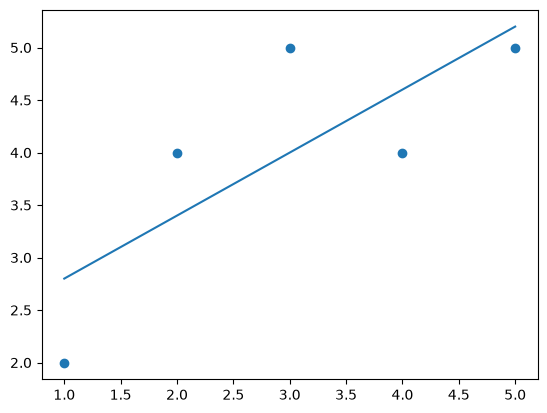

In [7]:
# 8th question 

import numpy as np
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

# Dataset
X = np.array([1, 2, 3, 4, 5]).reshape(-1, 1)
y = np.array([2, 4, 5, 4, 5])

# Train model
model = LinearRegression()
model.fit(X, y)

# Predict values
y_pred = model.predict(X)

# Display coefficients
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)
print("Prediction:", model.predict([[6]])[0])

# Plot regression line
plt.scatter(X, y)
plt.plot(X, y_pred)
plt.show()

In [26]:
# 9th one

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

# Load dataset
data = fetch_california_housing()

X = data.data
y = data.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create regression models
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42)
}

# Train and compare models
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print(name, "R2 Score:", r2_score(y_test, pred))


Linear Regression R2 Score: 0.5757877060324524
Decision Tree R2 Score: 0.622823312540521
Random Forest R2 Score: 0.8046244867176197


In [24]:
#10th one

import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Load dataset
df = pd.read_csv('online_retail.csv', encoding='latin1')

# Remove missing customer IDs
df = df.dropna(subset=['CustomerID'])

# Calculate purchase amount
df['Amount'] = df['Quantity'] * df['UnitPrice']

# Group customer data
customers = df.groupby('CustomerID').agg({
    'InvoiceNo': 'nunique',
    'Amount': 'sum'
})

# Rename columns
customers.columns = ['Frequency', 'Spending']

# Standardize data
X = StandardScaler().fit_transform(customers)

# Apply K-Means
model = KMeans(n_clusters=3, random_state=42, n_init=10)
customers['Cluster'] = model.fit_predict(X)

# Display customer groups
print(customers.head())


            Frequency  Spending  Cluster
CustomerID                              
12346.0             2      0.00        1
12347.0             7   4310.00        1
12348.0             4   1797.24        1
12349.0             1   1757.55        1
12350.0             1    334.40        1
